In [2]:
from xad.data import SENSOR_COLUMNS, load_skab

df = load_skab("../data/raw/SKAB")
print(df.shape)
print(df.groupby("scenario")["experiment"].nunique())
print("anomaly rate:", round(df["anomaly"].mean(), 3), "| changepoint rate:", round(df["changepoint"].mean(), 4))
print(df.isna().sum().sum(), "missing values")
df.head()

(37401, 12)
scenario
other     14
valve1    16
valve2     4
Name: experiment, dtype: int64
anomaly rate: 0.349 | changepoint rate: 0.0034
0 missing values


,Accelerometer1RMS,Accelerometer2RMS,Current,Pressure,Temperature,Thermocouple,Voltage,Volume Flow RateRMS,anomaly,changepoint,scenario,experiment
datetime,,,,,,,,,,,,
2020-03-09 10:14:33,0.026588,0.040111,1.33020,0.054711,79.3366,26.0199,233.062,32.0,0,0,valve1,valve1/0
2020-03-09 10:14:34,0.026170,0.040453,1.35399,0.382638,79.5158,26.0258,236.040,32.0,0,0,valve1,valve1/0
2020-03-09 10:14:35,0.026199,0.039419,1.54006,0.710565,79.3756,26.0265,251.380,32.0,0,0,valve1,valve1/0
2020-03-09 10:14:36,0.026027,0.039641,1.33458,0.382638,79.6097,26.0393,234.392,32.0,0,0,valve1,valve1/0
2020-03-09 10:14:37,0.026290,0.040273,1.07851,-0.273216,79.6109,26.0420,225.342,32.0,0,0,valve1,valve1/0


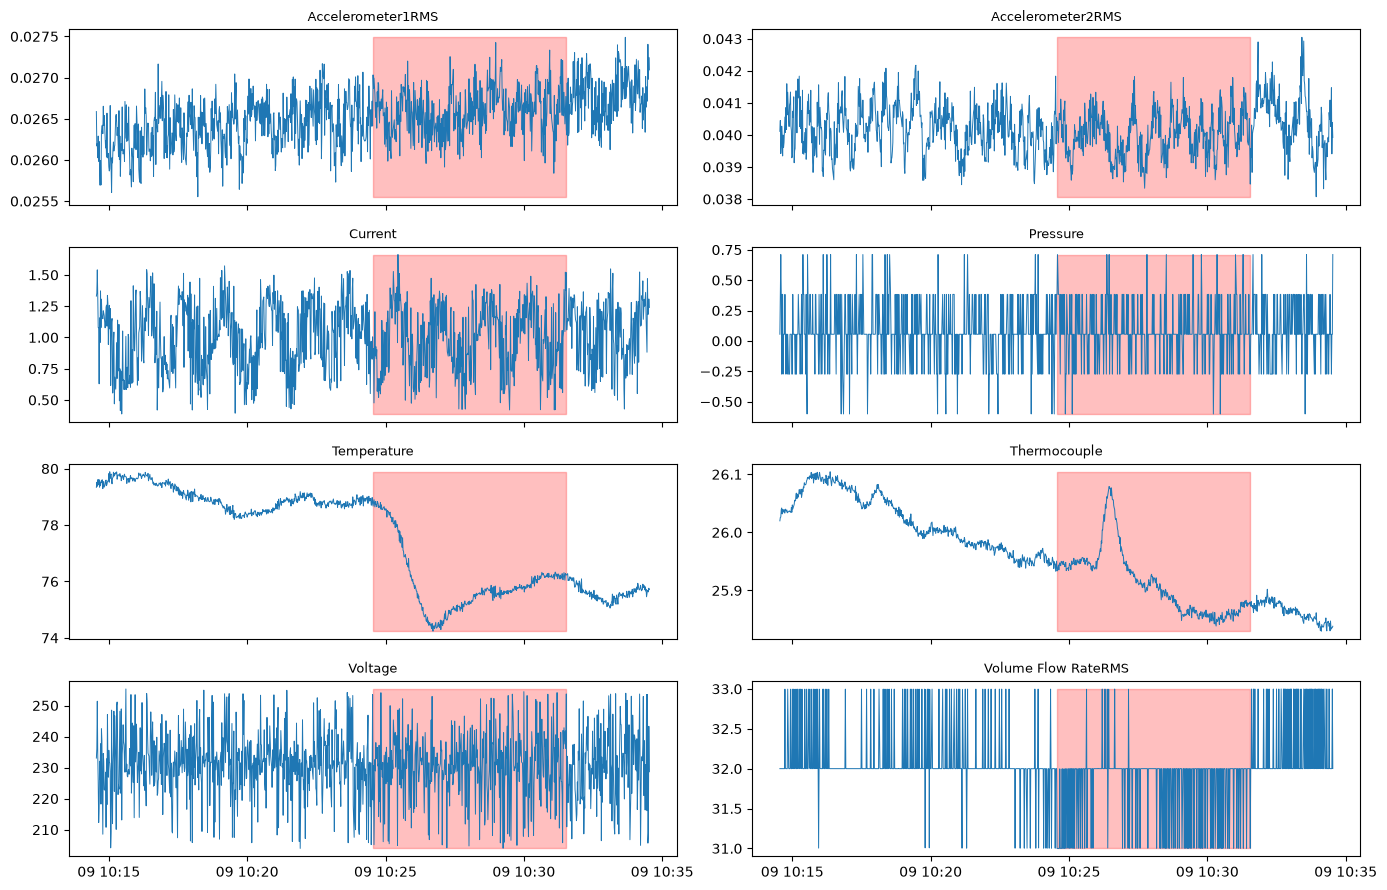

In [4]:
import matplotlib.pyplot as plt

exp = df[df["experiment"] == "valve1/0"]
fig, axes = plt.subplots(4, 2, figsize=(14, 9), sharex=True)
for ax, col in zip(axes.ravel(), SENSOR_COLUMNS):
    ax.plot(exp.index, exp[col], lw=0.7)
    ax.fill_between(exp.index, exp[col].min(), exp[col].max(),
                    where=exp["anomaly"] == 1, alpha=0.25, color="red")
    ax.set_title(col, fontsize=9)
plt.tight_layout()
fig.savefig("../docs/skab_valve1_0.png", dpi=120)

In [5]:
first = df.groupby("experiment").head(400)
print("anomalies in first 400 rows:", int(first["anomaly"].sum()))

per_exp = df.groupby("experiment").agg(
    rows=("anomaly", "size"),
    anomaly_rate=("anomaly", "mean"),
)
per_exp["first_anomaly_row"] = df.groupby("experiment")["anomaly"].apply(
    lambda s: int(s.values.argmax()) if s.any() else -1
)
print(per_exp.round(3).sort_values("first_anomaly_row").to_string())

anomalies in first 400 rows: 296
            rows  anomaly_rate  first_anomaly_row
experiment                                       
other/2      780         0.492                104
other/13     923         0.287                495
other/1      745         0.252                557
valve2/1    1063         0.313                560
valve2/0    1125         0.350                562
valve2/3     995         0.397                564
valve2/2    1129         0.350                565
valve1/2    1075         0.313                566
other/3     1137         0.350                568
other/12    1048         0.295                568
valve1/14   1139         0.350                569
other/10    1327         0.442                570
other/11    1190         0.379                570
valve1/13   1140         0.350                570
valve1/12   1140         0.350                570
other/14     905         0.334                571
other/8     1147         0.351                572
other/9     1144 